In [1]:
import numpy as np
import scanpy as sc
import torch

In [2]:
from loading import *
H3K27ac_ad, H3K27me3_ad = load_data_in_AnnData()

c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [3]:
from preprocessing import *
#test with random filtering and bin increase with H3K27ac
filt_H3K27ac = increase_bin_size(H3K27ac_ad, factor=150)

filt_H3K27ac = prevalence_filtering(filt_H3K27ac)

Number of bins with more than 50 cells having non-zero values: 30617


c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\anndata\_core\aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [4]:
#randomly split 
rng = np.random.default_rng(0)
filt_H3K27ac.obs["split_AE"] = np.where(rng.random(filt_H3K27ac.n_obs) < 0.8, "train", "val")

C:\Users\yvanb\AppData\Local\Temp\ipykernel_47680\550202969.py:3: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  filt_H3K27ac.obs["split_AE"] = np.where(rng.random(filt_H3K27ac.n_obs) < 0.8, "train", "val")


Train Epoch: 1-000 batch_loss=1.47e+01 
Train Epoch: 1-003 batch_loss=1.31e+01 
Train Epoch: 1-006 batch_loss=1.01e+01 
Train Epoch: 1-009 batch_loss=9.50e+00 
Train Epoch: 1-012 batch_loss=8.51e+00 
Train Epoch: 1-015 batch_loss=7.96e+00 
Train Epoch: 1-018 batch_loss=9.22e+00 
Train Epoch: 1-021 batch_loss=8.68e+00 
Train Epoch: 1-024 batch_loss=8.80e+00 
Train Epoch: 1-027 batch_loss=8.52e+00 
Clustering score for leiden :
 - NMI score : 0.262, ARI score : 0.068
 - ASW score : 0.639, LISI score (mean) : 1.184
Train Epoch: 2-000 batch_loss=7.34e+00 
Train Epoch: 2-003 batch_loss=8.05e+00 
Train Epoch: 2-006 batch_loss=8.02e+00 
Train Epoch: 2-009 batch_loss=7.59e+00 
Train Epoch: 2-012 batch_loss=7.99e+00 
Train Epoch: 2-015 batch_loss=7.83e+00 
Train Epoch: 2-018 batch_loss=7.29e+00 
Train Epoch: 2-021 batch_loss=8.14e+00 
Train Epoch: 2-024 batch_loss=7.78e+00 
Train Epoch: 2-027 batch_loss=7.13e+00 
Clustering score for leiden :
 - NMI score : 0.352, ARI score : 0.123
 - ASW score

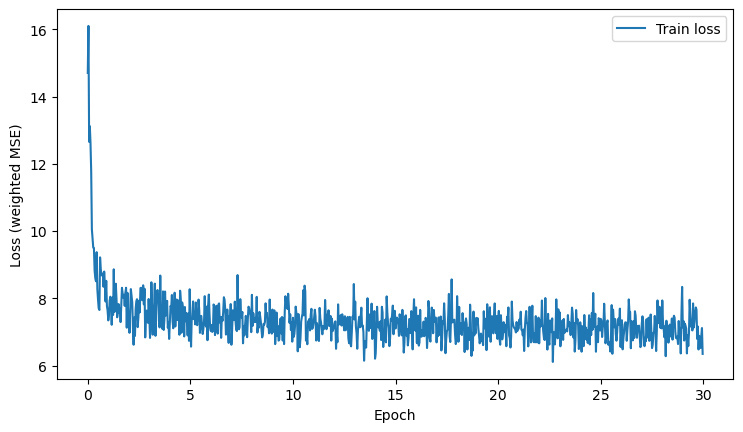

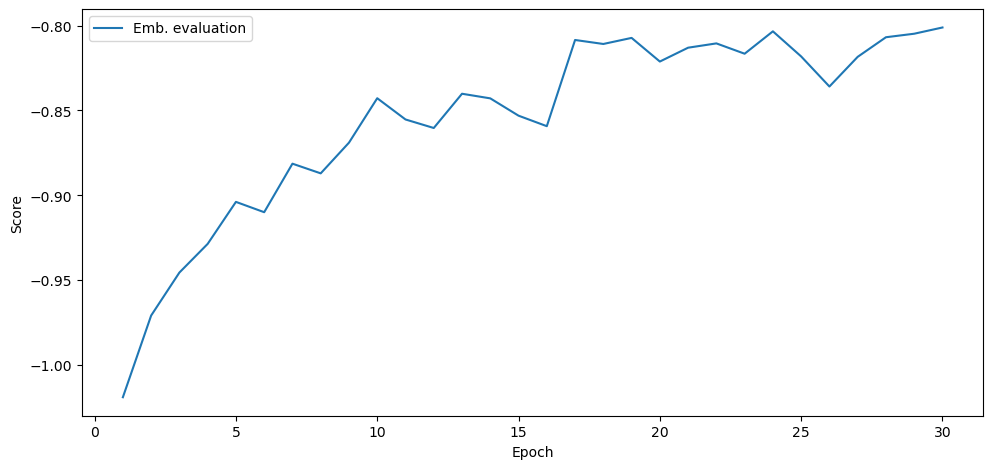

Loss finale : 6.348621845245361
Scores d'éval : [np.float64(-1.0192618097792865), np.float64(-0.9710438644441871), np.float64(-0.9456650186371152), np.float64(-0.9287528909830007), np.float64(-0.9039576711752533), np.float64(-0.9100526813836057), np.float64(-0.881413531326162), np.float64(-0.887126210687486), np.float64(-0.8690042093655748), np.float64(-0.8427798504922799), np.float64(-0.8553167016278502), np.float64(-0.8603513776688493), np.float64(-0.8401355060513505), np.float64(-0.8428602074685825), np.float64(-0.853081589871761), np.float64(-0.8592792617029935), np.float64(-0.8084024553039351), np.float64(-0.8107585336664905), np.float64(-0.8071688077111265), np.float64(-0.8211275153731858), np.float64(-0.8129538284829539), np.float64(-0.8104155626898975), np.float64(-0.8165107327808785), np.float64(-0.8032985758714997), np.float64(-0.8181229832048847), np.float64(-0.8358663486009654), np.float64(-0.8183522605871086), np.float64(-0.80678138271213), np.float64(-0.8047070307557804),

In [6]:
#quick test with small epochs
from autoencoder import *
model, train_loss, eval_hist = run_training(
    model_class=AutoEncoder,
    model_kwargs=dict(input_dim = filt_H3K27ac.n_vars, latent_dim=25),
    num_epochs=30,
    optimizer_kwargs=dict(lr=1e-3, weight_decay=1e-4),
    anndata=filt_H3K27ac,
    batch_size=128,
    device="cuda" if torch.cuda.is_available() else "cpu",
)

print("Loss finale :", train_loss[-1])
print("Scores d'éval :", eval_hist)
print("Embedding :", filt_H3K27ac.obsm["X_AE"].shape) 

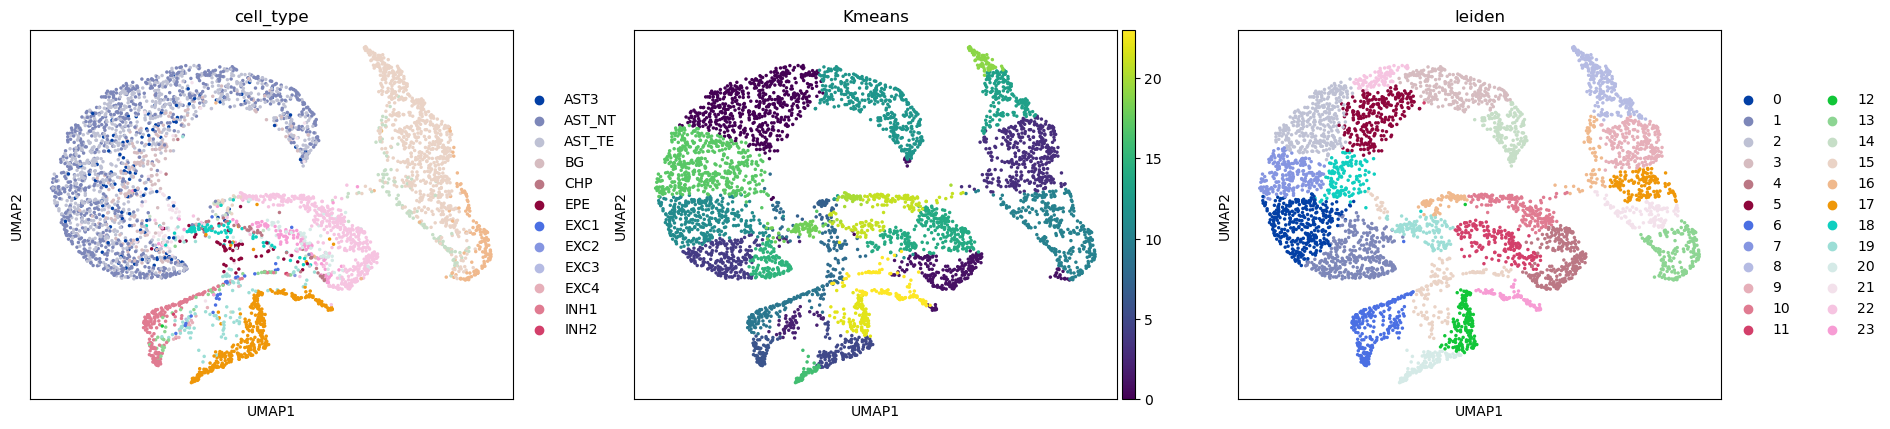

In [9]:
from clustering import *
device="cuda" if torch.cuda.is_available() else "cpu"
filt_H3K27ac.obsm['X_AE'] = extract_emb(model, device, filt_H3K27ac.X, 128)
clustering(filt_H3K27ac, visualization=True, type_obs='X_AE')




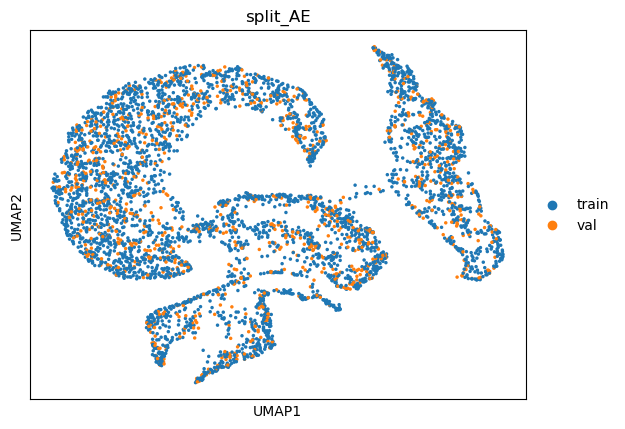

In [10]:
import scanpy as sc
sc.tl.umap(filt_H3K27ac, neighbors_key='nn_lsi')
sc.pl.umap(filt_H3K27ac, color='split_AE')

In [ ]:
#tuning
import torch, pandas as pd

rows = []
for wnz in [1, 10, 50]:
    for ld in [10, 20, 64]:
        for seed in [0, 1]:
            torch.manual_seed(seed)
            _, _, hist = run_training(
                AutoEncoder, dict(input_dim=filt_H3K27ac.n_vars, latent_dim=ld),
                15, dict(lr=1e-3, weight_decay=1e-4), filt_H3K27ac, 128,
                weight_no_zero=wnz, plot=False)
            rows.append(dict(wnz=wnz, latent_dim=ld, seed=seed, score=hist[-1]))

res = pd.DataFrame(rows)
print(res.groupby(["wnz", "latent_dim"]).score.agg(["mean", "std"]).sort_values("mean", ascending=False))